In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import label_binarize

# Ajustado para 3 níveis (.parent.parent.parent) conforme o novo caminho em src/trainings/decision_tree/
BASE_DIR = Path.cwd().parent.parent.parent

# 1. Carregamento dos dados divididos (usamos os dados brutos sem escalonamento)
X_train = pd.read_csv(BASE_DIR / "data/processed/X_train.csv")
X_test = pd.read_csv(BASE_DIR / "data/processed/X_test.csv")
y_train = pd.read_csv(BASE_DIR / "data/processed/y_train.csv").values.ravel()
y_test = pd.read_csv(BASE_DIR / "data/processed/y_test.csv").values.ravel()

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Número de features: {X_train.shape[1]}")

X_train shape: (10648, 24) | X_test shape: (4564, 24)
Número de features: 24


In [2]:
# 1. Baseline com critério de Gini e balanceamento de classes
dt_baseline = DecisionTreeClassifier(class_weight="balanced", random_state=42)

# 2. Treinamento
dt_baseline.fit(X_train, y_train)

# 3. Predição e avaliação no conjunto de teste
y_pred_base = dt_baseline.predict(X_test)

target_names = [
    "Sem Anemia (0)",
    "HGB (1)",
    "Ferro (2)",
    "Folato (3)",
    "B12 (4)",
]

print("--- Relatório de Classificação: Decision Tree Baseline ---")
print(
    classification_report(
        y_test, y_pred_base, target_names=target_names, digits=4
    )
)
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_base))

--- Relatório de Classificação: Decision Tree Baseline ---
                precision    recall  f1-score   support

Sem Anemia (0)     0.9993    0.9990    0.9991      2902
       HGB (1)     0.9967    0.9967    0.9967       304
     Ferro (2)     0.9968    0.9992    0.9980      1253
    Folato (3)     0.9545    0.9130    0.9333        46
       B12 (4)     1.0000    1.0000    1.0000        59

      accuracy                         0.9980      4564
     macro avg     0.9895    0.9816    0.9854      4564
  weighted avg     0.9980    0.9980    0.9980      4564

Matriz de Confusão:
[[2899    0    1    2    0]
 [   0  303    1    0    0]
 [   0    1 1252    0    0]
 [   2    0    2   42    0]
 [   0    0    0    0   59]]


In [3]:
# 1. Grade de hiperparâmetros para podar e regularizar a árvore
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
}

# 2. Validação cruzada estratificada (5 folds)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Grid Search focado em f1_macro
base_dt_grid = DecisionTreeClassifier(
    class_weight="balanced", random_state=42
)

grid_search_dt = GridSearchCV(
    estimator=base_dt_grid,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True,  # Já retreina no treino completo com a melhor configuração
)

print("Iniciando busca em grade para Decision Tree...")
grid_search_dt.fit(X_train, y_train)

print("\n--- Melhores Hiperparâmetros ---")
print(f"Parâmetros: {grid_search_dt.best_params_}")
print(f"Melhor F1-Macro (CV): {grid_search_dt.best_score_:.4f}")

Iniciando busca em grade para Decision Tree...
Fitting 5 folds for each of 192 candidates, totalling 960 fits

--- Melhores Hiperparâmetros ---
Parâmetros: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 20}
Melhor F1-Macro (CV): 0.9931


In [4]:
# 1. Recupera o melhor estimador já ajustado
best_dt = grid_search_dt.best_estimator_

# 2. Predição no conjunto de teste
y_pred_opt = best_dt.predict(X_test)

print("--- Relatório de Classificação (Decision Tree Otimizada) ---")
print(
    classification_report(
        y_test, y_pred_opt, target_names=target_names, digits=4
    )
)
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_opt))

--- Relatório de Classificação (Decision Tree Otimizada) ---
                precision    recall  f1-score   support

Sem Anemia (0)     0.9997    0.9993    0.9995      2902
       HGB (1)     1.0000    0.9967    0.9984       304
     Ferro (2)     0.9960    1.0000    0.9980      1253
    Folato (3)     1.0000    0.9348    0.9663        46
       B12 (4)     1.0000    1.0000    1.0000        59

      accuracy                         0.9987      4564
     macro avg     0.9991    0.9862    0.9924      4564
  weighted avg     0.9987    0.9987    0.9987      4564

Matriz de Confusão:
[[2900    0    2    0    0]
 [   0  303    1    0    0]
 [   0    0 1253    0    0]
 [   1    0    2   43    0]
 [   0    0    0    0   59]]


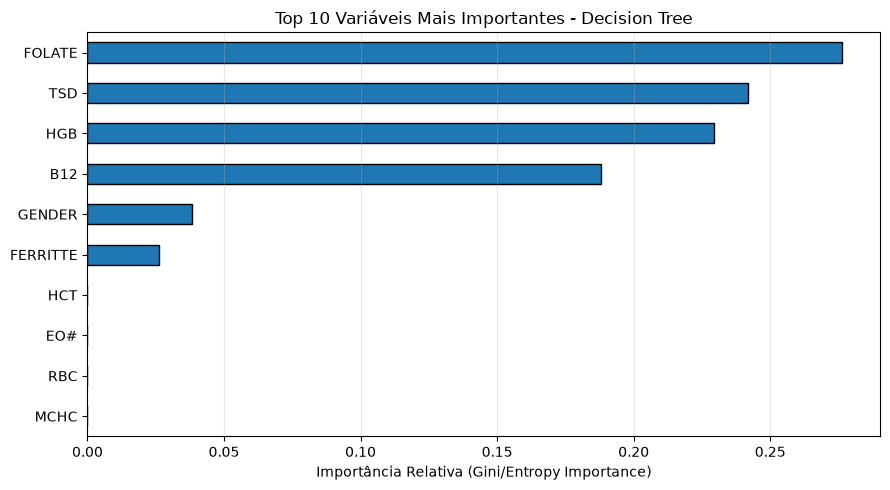

Top 5 Variáveis Mais Relevantes:
FOLATE    0.276356
TSD       0.241856
HGB       0.229330
B12       0.188084
GENDER    0.038162
dtype: float64


In [5]:
outputs_dir = BASE_DIR / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

# 1. DataFrame de importância
feat_importances = pd.Series(
    best_dt.feature_importances_, index=X_train.columns
)
top_feats = feat_importances.sort_values(ascending=False).head(10)

# 2. Gráfico de barras horizontais
plt.figure(figsize=(9, 5))
top_feats.sort_values().plot(kind="barh", color="#1f77b4", edgecolor="black")
plt.title("Top 10 Variáveis Mais Importantes - Decision Tree")
plt.xlabel("Importância Relativa (Gini/Entropy Importance)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    outputs_dir / "decision_tree_feature_importance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Top 5 Variáveis Mais Relevantes:")
print(top_feats.head(5))

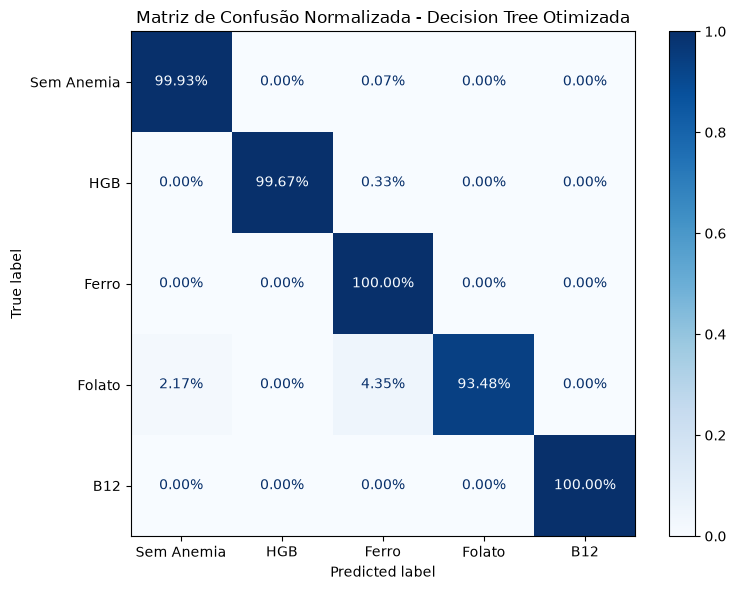

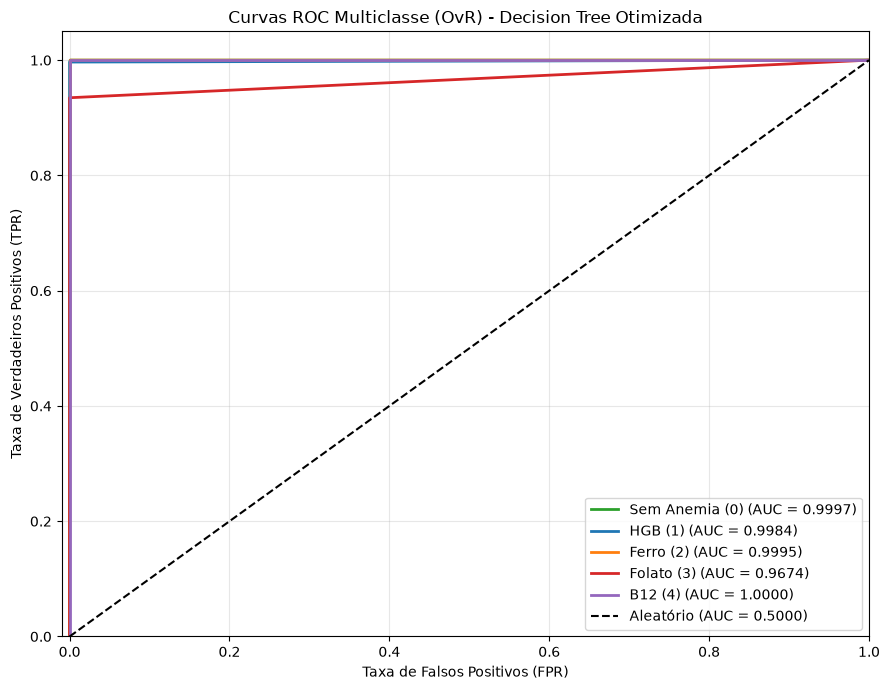

ROC AUC Score (Macro OvR): 0.9930
ROC AUC Score (Weighted OvR): 0.9992


In [7]:
# 1. Matriz de Confusão Normalizada
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_opt,
    display_labels=["Sem Anemia", "HGB", "Ferro", "Folato", "B12"],
    cmap="Blues",
    normalize="true",
    values_format=".2%",
    ax=ax,
)
plt.title("Matriz de Confusão Normalizada - Decision Tree Otimizada")
plt.tight_layout()
plt.savefig(
    outputs_dir / "decision_tree_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# 2. Curvas ROC One-vs-Rest
n_classes = len(target_names)
y_prob_opt = best_dt.predict_proba(X_test)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728", "#9467bd"]

for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_opt[:, i])
    auc_score = roc_auc_score(y_test_bin[:, i], y_prob_opt[:, i])
    ax.plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{target_names[i]} (AUC = {auc_score:.4f})",
    )

ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Aleatório (AUC = 0.5000)")
ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("Taxa de Falsos Positivos (FPR)")
ax.set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
ax.set_title("Curvas ROC Multiclasse (OvR) - Decision Tree Otimizada")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    outputs_dir / "decision_tree_roc_curves.png", dpi=300, bbox_inches="tight"
)
plt.show()

# 3. Métricas Globais AUC
auc_macro = roc_auc_score(
    y_test_bin, y_prob_opt, average="macro", multi_class="ovr"
)
auc_weighted = roc_auc_score(
    y_test_bin, y_prob_opt, average="weighted", multi_class="ovr"
)
print(f"ROC AUC Score (Macro OvR): {auc_macro:.4f}")
print(f"ROC AUC Score (Weighted OvR): {auc_weighted:.4f}")

In [8]:
models_dir = BASE_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "decision_tree_optimized.pkl"
joblib.dump(best_dt, model_path)

print(f"Modelo salvo com sucesso em: {model_path}")

Modelo salvo com sucesso em: Z:\anemia_ml_project\models\decision_tree_optimized.pkl
